In [1]:
from greenbowl_chi import (load_my_experiment, BASKETS,
                           INTENDED_SPLIT, ALPHA)
import numpy as np
import warnings
import matplotlib.pyplot as plt
import matplotlib_inline
import seaborn as sns
from scipy.stats import chisquare, chi2_contingency, fisher_exact
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore")
matplotlib_inline.backend_inline.set_matplotlib_formats("svg")

In [2]:
STUDENT_ID = "ozhelezniakov@kse.org.ua"   # <-- put YOUR id here
exp = load_my_experiment(STUDENT_ID)

print(exp)                                  # arm sizes + intended split
print(exp.data.head())                      # one row per order: arm, basket, city
table = exp.table()                         # 2 x 5 counts: rows control/test
print("rows = [control, test], cols =", BASKETS)
print(table)

<Experiment n_control=4097 n_test=4097 intended=50%/50%>
       arm    basket  city
0  control   Economy  Lviv
1  control     Large  Kyiv
2  control   Premium  Lviv
3  control  Standard  Lviv
4  control   Economy  Kyiv
rows = [control, test], cols = ['Economy', 'Standard', 'Large', 'Premium', 'VIP']
[[1693 1271  655  407   71]
 [1590 1182  761  506   58]]


In [3]:
data_table = exp.data.pivot_table(index="arm", columns="basket", aggfunc="count")
data_table.columns = data_table.columns.droplevel(0)
data_table.sort_values("control", axis=1, ascending=False, inplace=True)
data_table

basket,Economy,Standard,Large,Premium,VIP
arm,,,,,
control,1693,1271,655,407,71
test,1590,1182,761,506,58


In [4]:
chi2_contingency_result = chi2_contingency(table)

print("\t Chi2 contingency test")
print(f"Chi2-stats: {chi2_contingency_result.statistic:.3f}")
print(f"p-value: {chi2_contingency_result.pvalue:.3f}")

	 Chi2 contingency test
Chi2-stats: 26.441
p-value: 0.000


## SRM Check
---
* Сворюємо функція для перевірки правильності сплітування
* Але без функції видно, що сплітування працює правильно бо вибірки рівно 50/50
* Звісно тест показва, що сплітуання працює коректно

In [5]:
def srm_check(n_test, n_control, intended=INTENDED_SPLIT, alpha=0.05):

    expected_control = (n_test + n_control) * intended[0]
    expected_test = (n_test + n_control) * intended[1]
    observed_frecensy = np.array([n_test, n_control])
    expected_frecensy = np.array([expected_test, expected_control])

    result = chisquare(observed_frecensy, expected_frecensy)

    p_value = result.pvalue
    chi2_stat = result.statistic
    if p_value < alpha:
        verdict = "⛔ reject indepented splitt"
    else:
        verdict = "✅ indepented split"

    return {"n_test": n_test,
            "expected_test": expected_test,
            "n_conrol": n_control,
            "expected_control": expected_control,
            "p_value": p_value,
            "chi2_stat": chi2_stat,
            "verdict": verdict}

In [6]:
srm_check_reesult = srm_check(exp.n_test, exp.n_control, alpha=ALPHA)
print("\t SRM check")
print(f" N test: {srm_check_reesult["n_test"]} \t N expected test: {srm_check_reesult["expected_test"]:.0f}")
print(f" N control: {srm_check_reesult["n_conrol"]} \t N expected control: {srm_check_reesult["expected_control"]:.0f}")
print(f"p-value: {srm_check_reesult['p_value']:.3f}")
print(f"chi2_stat: {srm_check_reesult['chi2_stat']:.3f}")
print(srm_check_reesult["verdict"])

	 SRM check
 N test: 4097 	 N expected test: 4097
 N control: 4097 	 N expected control: 4097
p-value: 1.000
chi2_stat: 0.000
✅ indepented split


## Homogeneity Test
---
* Створюємо функція для перевірки на гомогеність `homogeneity_test`.
* Вона повертає `chi2_stat`, `p_value`, `df` та не повертає `Cramers-V`
* Ми можемо бачити різниця є `p-value < 0.05` тобто тестова та контрольна групи не гомогені
* Поки ми не можемо оцінити розмір ефекту

In [7]:
def homogeneity_test(table, alpha=ALPHA):
    """Version 2. Chi-square independence / homogeneity test for a table."""
    table = np.asarray(table, float)
    chi2_stat, p_value, dof, expected = chi2_contingency(table)
    verdict = ("⛔ reject independence → the variables ARE related"
               if p_value <= alpha else
               "✅ do not reject → no association visible")
    return {"chi2_stat": chi2_stat, "df": dof, "p_value": p_value,
            "min_expected": expected.min(), "expected": expected,
            "verdict": verdict}

In [8]:
homogeneity_test_result = homogeneity_test(table)

print("\t Homogeneity test")
print(f"chi2 stats: {homogeneity_test_result['chi2_stat']:.3f}")
print(f"p-value: {homogeneity_test_result['p_value']:.3f}")
print(f"df: {homogeneity_test_result['df']}")
print(f"min_expected: {homogeneity_test_result['min_expected']:.1f}")
print(homogeneity_test_result["verdict"])

	 Homogeneity test
chi2 stats: 26.441
p-value: 0.000
df: 4
min_expected: 64.5
⛔ reject independence → the variables ARE related


## Нew version
---
* Створємо 3 версію, яка також повертає `Cramers V`
* Створюємо 4 версію, яка переключається на розподіл Фішера, якщо вибірка малелкнька

**Поки можемо бачити, що різниця**

In [9]:
def homogeneity_report(table, alpha=ALPHA):
    """Version 3. Chi-square independence / homogeneity test for a table."""
    table = np.asarray(table, float)
    chi2_stat, p_value, dof, expected = chi2_contingency(table)
    cramers_v = np.sqrt(chi2_stat / (table.sum() * (min(table.shape) - 1)))
    match cramers_v:
        case x if x < 0.1: strength = "None"
        case x if x < 0.2: strength = "weak"
        case x if x < 0.4: strength = "moderate"
        case  x if x >= 0.4: strength = "strong"

    verdict = (f"⛔ reject independence → the variables ARE related \n with {strength} strength "
               if p_value <= alpha else
               f"✅ do not reject → no association visible \n with {strength} strength ")
    return {"chi2_stat": chi2_stat, "df": dof, "p_value": p_value,
            "min_expected": expected.min(), "expected": expected,
            "verdict": verdict, "cramers_v": cramers_v}

In [10]:
homogeneity_report_result = homogeneity_report(table)

print("\t Homogeneity test")
print(f"chi2 stats: {homogeneity_report_result['chi2_stat']:.3f}")
print(f"p-value: {homogeneity_report_result['p_value']:.3f}")
print(f"df: {homogeneity_report_result['df']}")
print(f"Cramers-V: {homogeneity_report_result['cramers_v']:.3f}")
print(f"min_expected: {homogeneity_report_result['min_expected']:.1f}")
print(homogeneity_report_result["verdict"])

	 Homogeneity test
chi2 stats: 26.441
p-value: 0.000
df: 4
Cramers-V: 0.057
min_expected: 64.5
⛔ reject independence → the variables ARE related 
 with None strength 


In [11]:
def safe_homogeneity(table, alpha=ALPHA):
    """Version 4. Chi-square independence / homogeneity test for a table."""
    table = np.asarray(table, float)
    expected = chi2_contingency(table)[3]

    if table.shape == (2, 2) and expected.min() < 5:
        expected = chi2_contingency(table)[3]
        odds, p_value = fisher_exact(table)
        verdict = ("⛔ reject (Fisher)" if p_value <= alpha
                   else "✅ do not reject (Fisher)")
        return {"test": "Fisher exact", "p": p_value, "odds_ratio": odds,
                    "min_expected": expected.min(), "verdict": verdict}

    chi2_stat, p_value, dof, expected = chi2_contingency(table)

    cramers_v = np.sqrt(chi2_stat / (table.sum() * (min(table.shape) - 1)))

    match cramers_v:
        case x if x < 0.1: strength = "None"
        case x if x < 0.2: strength = "weak"
        case x if x < 0.4: strength = "moderate"
        case x if x >= 0.4: strength = "strong"

    verdict = (f"⛔ reject independence → the variables ARE related with {strength} strength "
               if p_value <= alpha else
               f"✅ do not reject → no association visible")
    return {"test": "chi2", "chi2_stat": chi2_stat, "df": dof, "p_value": p_value,
            "min_expected": expected.min(), "expected": expected,
            "verdict": verdict, "cramers_v": cramers_v}

In [12]:
homogeneity_report_result = safe_homogeneity(table)

print("\t Homogeneity test (or Fisher exact)")
print(f"chi2 stats: {homogeneity_report_result['chi2_stat']:.3f}")
print(f"p-value: {homogeneity_report_result['p_value']:.3f}")
print(f"df: {homogeneity_report_result['df']}")
print(f"Cramers-V: {homogeneity_report_result['cramers_v']:.3f}")
print(f"min_expected: {homogeneity_report_result['min_expected']:.1f}")
print(homogeneity_report_result["verdict"])

	 Homogeneity test (or Fisher exact)
chi2 stats: 26.441
p-value: 0.000
df: 4
Cramers-V: 0.057
min_expected: 64.5
⛔ reject independence → the variables ARE related with None strength 


### HeatMap

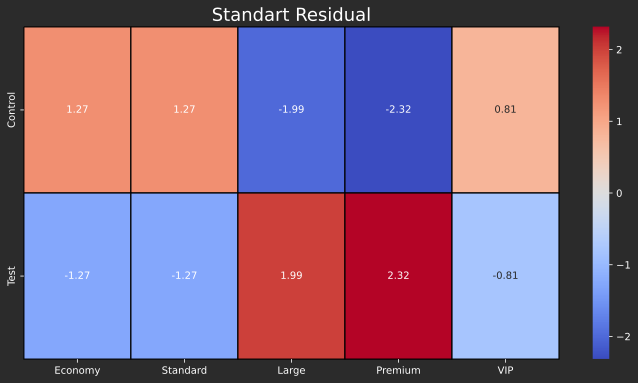

In [13]:
expected = chi2_contingency(table)[3]
standart_residual = (table - expected) / np.sqrt(expected)

fig, ax = plt.subplots(figsize = (12, 6))

sns.heatmap(standart_residual,
            annot=True,
            cmap="coolwarm",
            ax=ax,
            xticklabels=data_table.columns,
            yticklabels=[w.capitalize() for w in data_table.index.tolist()],
            linewidths=1.2,
            linecolor="black",
            fmt='.2f')

ax.set_title("Standart Residual", size = 18)
plt.show()

## Homogeneity Test for `City`
---
* Перевіряємо чи є різниця між містами
* Ми можемо бачити, що різниця є `p-value < 0.05`
* Тому ми розбиваємо та робимо тест для кожного міста окремо можемо бачити, що для кожного міста різниці немо
* Повторюємо теж саме але для сигментів. Можна побачити, що різниця є для всіх окрім `VIP`

**Тому реального ефекту нема**

In [14]:
data_table_city  = exp.data.pivot_table(index="arm", columns="city", aggfunc="count")
data_table_city.columns = data_table_city.columns.droplevel(0)
data_table_city.sort_values("control", axis=1, ascending=False, inplace=True)
data_table_city_num = data_table_city.to_numpy()
data_table_city

city,Kyiv,Odesa,Lviv,Kharkiv
arm,,,,
control,1663,872,823,739
test,1054,579,2023,441


In [15]:
homogeneity_report_result = safe_homogeneity(data_table_city_num)

print("\t Homogeneity test (or Fisher exact)")
print(f"chi2 stats: {homogeneity_report_result['chi2_stat']:.3f}")
print(f"p-value: {homogeneity_report_result['p_value']:.3f}")
print(f"df: {homogeneity_report_result['df']}")
print(f"Cramers-V: {homogeneity_report_result['cramers_v']:.3f}")
print(f"min_expected: {homogeneity_report_result['min_expected']:.1f}")
print(homogeneity_report_result["verdict"])

	 Homogeneity test (or Fisher exact)
chi2 stats: 776.900
p-value: 0.000
df: 3
Cramers-V: 0.308
min_expected: 590.0
⛔ reject independence → the variables ARE related with moderate strength 


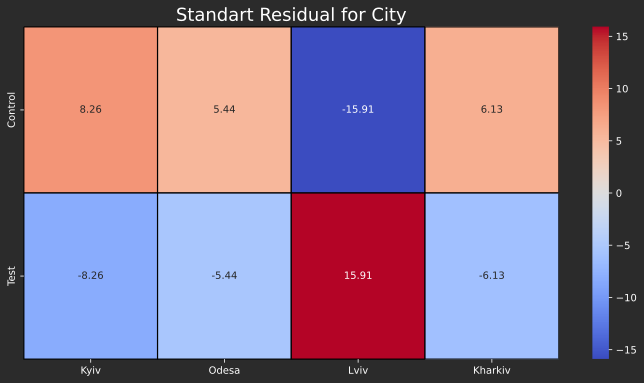

In [16]:
expected = chi2_contingency(data_table_city_num)[3]
standart_residual = (data_table_city_num - expected) / np.sqrt(expected)

fig, ax = plt.subplots(figsize = (12, 6))

sns.heatmap(standart_residual,
            annot=True,
            cmap="coolwarm",
            ax=ax,
            xticklabels=data_table_city.columns,
            yticklabels=[w.capitalize() for w in data_table_city.index.tolist()],
            linewidths=1.2,
            linecolor="black",
            fmt='.2f')

ax.set_title("Standart Residual for City", size = 18)
plt.show()

In [17]:
print("\t Homogeneity test (or Fisher exact) for each city ")
alpha = ALPHA / 4
print(f"\t alpha = {alpha:.3f}")
for i in exp.data.city.unique():
    data_table = exp.data[exp.data.city == i].pivot_table(index="arm", columns="basket", aggfunc="count")
    data_table.columns = data_table.columns.droplevel(0)
    data_table.sort_values("control", axis=1, ascending=False, inplace=True)
    homogeneity_report_result = safe_homogeneity(data_table, alpha=alpha)
    print(f"City: {i:>7} \t chi2 stats: {homogeneity_report_result['chi2_stat']:>7.3f} \t p-value: {homogeneity_report_result['p_value']:>7.3f} \t verdict: {homogeneity_report_result['verdict']}")

	 Homogeneity test (or Fisher exact) for each city 
	 alpha = 0.013
City:    Lviv 	 chi2 stats:   6.614 	 p-value:   0.158 	 verdict: ✅ do not reject → no association visible
City:    Kyiv 	 chi2 stats:   1.989 	 p-value:   0.738 	 verdict: ✅ do not reject → no association visible
City: Kharkiv 	 chi2 stats:   1.935 	 p-value:   0.748 	 verdict: ✅ do not reject → no association visible
City:   Odesa 	 chi2 stats:  10.043 	 p-value:   0.040 	 verdict: ✅ do not reject → no association visible


In [18]:
print("\t Homogeneity test (or Fisher exact) for each Basket")
alpha = ALPHA / 5
print(f"\t alpha = {alpha:.2f}")
for i in exp.data.basket.unique():
    data_table = exp.data[exp.data.basket == i].pivot_table(index="arm", columns="city", aggfunc="count")
    data_table.columns = data_table.columns.droplevel(0)
    data_table.sort_values("control", axis=1, ascending=False, inplace=True)
    homogeneity_report_result = safe_homogeneity(data_table, alpha=alpha)
    print(f"Basket: {i} chi2-stats: {homogeneity_report_result['chi2_stat']:.3f} p-value: {homogeneity_report_result['p_value']:.3f}  verdict: {homogeneity_report_result['verdict']}")

	 Homogeneity test (or Fisher exact) for each Basket
	 alpha = 0.01
Basket: Economy chi2-stats: 267.268 p-value: 0.000  verdict: ⛔ reject independence → the variables ARE related with moderate strength 
Basket: Large chi2-stats: 128.111 p-value: 0.000  verdict: ⛔ reject independence → the variables ARE related with moderate strength 
Basket: Premium chi2-stats: 99.775 p-value: 0.000  verdict: ⛔ reject independence → the variables ARE related with moderate strength 
Basket: Standard chi2-stats: 269.656 p-value: 0.000  verdict: ⛔ reject independence → the variables ARE related with moderate strength 
Basket: VIP chi2-stats: 7.003 p-value: 0.072  verdict: ✅ do not reject → no association visible


In [19]:
def gof_fpr(probs, n_per_arm, n_exps=10_000, alpha=0.05, seed=73):
    """FPR of the goodness-of-fit test under H0 (data from the same probs)."""
    rng = np.random.default_rng(seed)
    expected = n_per_arm * np.asarray(probs, float)

    rej = sum(chisquare(rng.multinomial(n_per_arm, probs), f_exp=expected).pvalue < alpha
              for _ in range(n_exps))
    ci_low, ci_high = proportion_confint(rej, n_exps, alpha=0.05, method="wilson")
    return {"fpr": rej / n_exps, "ci_low": ci_low, "ci_high":ci_high, "min_expected": expected.min()}

In [20]:
n_per_arm = 10
print("\tMonte-Carl FPR test")
for n_per_arm in range(100, 2100, 100):
    gof_fpr_result = gof_fpr(np.repeat(1/6, 6),  n_per_arm = n_per_arm)
    print(f"n: {n_per_arm:>4} \t FPR: {gof_fpr_result["fpr"]:.3f} \t CI low: {gof_fpr_result["ci_low"]:.3f} \t CI high: {gof_fpr_result["ci_high"]:.3f}", end="")
    print("\t ✅ FPR in CI" if gof_fpr_result["ci_low"] < gof_fpr_result["fpr"] < gof_fpr_result["ci_high"] else "⛔ FPR not in CI")



	Monte-Carl FPR test
n:  100 	 FPR: 0.050 	 CI low: 0.046 	 CI high: 0.054	 ✅ FPR in CI
n:  200 	 FPR: 0.052 	 CI low: 0.048 	 CI high: 0.056	 ✅ FPR in CI
n:  300 	 FPR: 0.050 	 CI low: 0.046 	 CI high: 0.055	 ✅ FPR in CI
n:  400 	 FPR: 0.052 	 CI low: 0.047 	 CI high: 0.056	 ✅ FPR in CI
n:  500 	 FPR: 0.048 	 CI low: 0.044 	 CI high: 0.052	 ✅ FPR in CI
n:  600 	 FPR: 0.051 	 CI low: 0.047 	 CI high: 0.055	 ✅ FPR in CI
n:  700 	 FPR: 0.051 	 CI low: 0.046 	 CI high: 0.055	 ✅ FPR in CI
n:  800 	 FPR: 0.048 	 CI low: 0.044 	 CI high: 0.052	 ✅ FPR in CI
n:  900 	 FPR: 0.051 	 CI low: 0.046 	 CI high: 0.055	 ✅ FPR in CI
n: 1000 	 FPR: 0.049 	 CI low: 0.045 	 CI high: 0.054	 ✅ FPR in CI
n: 1100 	 FPR: 0.048 	 CI low: 0.044 	 CI high: 0.052	 ✅ FPR in CI
n: 1200 	 FPR: 0.048 	 CI low: 0.044 	 CI high: 0.052	 ✅ FPR in CI
n: 1300 	 FPR: 0.048 	 CI low: 0.044 	 CI high: 0.052	 ✅ FPR in CI
n: 1400 	 FPR: 0.051 	 CI low: 0.046 	 CI high: 0.055	 ✅ FPR in CI
n: 1500 	 FPR: 0.049 	 CI low: 0.045 	 CI

## Тест валідний